In [ ]:
# ⭐ Project 7:  Card Fraud Detection - Random Forest

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

data = pd.read_csv("creditcard.csv")
df1 = pd.DataFrame(data)
df = df1.copy()
df


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [ ]:
# EDA process
print(df.head())
print(df.shape)
print(df.columns)
print(df.info())
print(df.describe())
print(df.isnull().sum())

In [ ]:
# Model features

x = df.drop("Class", axis=1)
y = df["Class"]

x_train,x_test,y_train,y_test = train_test_split(x, y, test_size= 0.20, random_state= 42, stratify= y)



In [ ]:
# Model Train

model = RandomForestClassifier(n_estimators= 100, random_state= 42)

model.fit(x_train,y_train)



RandomForestClassifier(random_state=42)

In [ ]:
# Model Perfomance Testing

y_pred = model.predict(x_test)
accuracy = accuracy_score(y_test,y_pred)

print("The model Prediction : ",y_pred[0])
print(f"The model Accuracy   : {accuracy*100:.2f}")

if y_pred[0]==0:
    print(">"*28)
    print("    Transaction is Valid")
    print("<"*28)
else:
    print(">"*28)
    print("    Transaction is Fraud")
    print("<"*28)

The model Prediction :  0
The model Accuracy   : 99.96
>>>>>>>>>>>>>>>>>>>>>>>>>>>>
    Transaction is Valid
<<<<<<<<<<<<<<<<<<<<<<<<<<<<


/tmp/ipykernel_3200/3851066197.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Class', data=df, palette='Set2')


([<matplotlib.axis.XTick at 0x7bb7a084b890>,
 [Text(0, 0, 'Valid (0)'), Text(1, 0, 'Fraud (1)')])

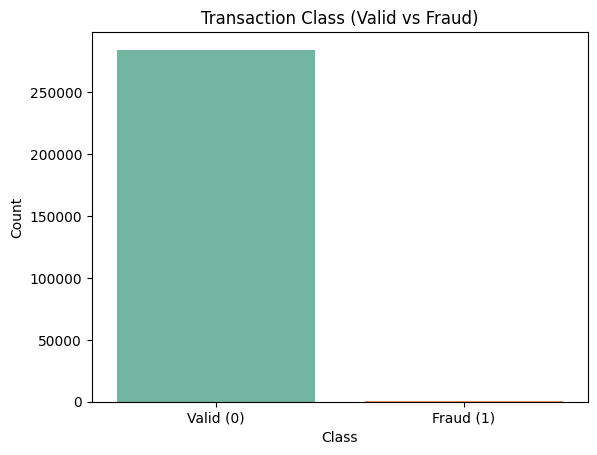

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='Class', data=df, palette='Set2')

plt.title('Transaction Class (Valid vs Fraud)')
plt.xlabel('Class')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['Valid (0)', 'Fraud (1)'])